# Interactive Visual Analytics - Launch Site Locations (Folium)

Objectives:
1. Mark all launch sites on an interactive map
2. Color each launch record by landing outcome
3. Analyze proximity to coastline, railway and highways

In [1]:
import folium, pandas as pd
from folium.plugins import MarkerCluster

geo = pd.read_csv("data/spacex_launch_geo.csv")
sites = geo[["LaunchSite", "Lat", "Long"]].drop_duplicates().reset_index(drop=True)
print(sites.to_string(index=False))

 LaunchSite     Lat      Long
CCAFS LC-40 28.5623  -80.5774
 KSC LC-39A 28.6084  -80.6043
VAFB SLC-4E 34.6321 -120.6107

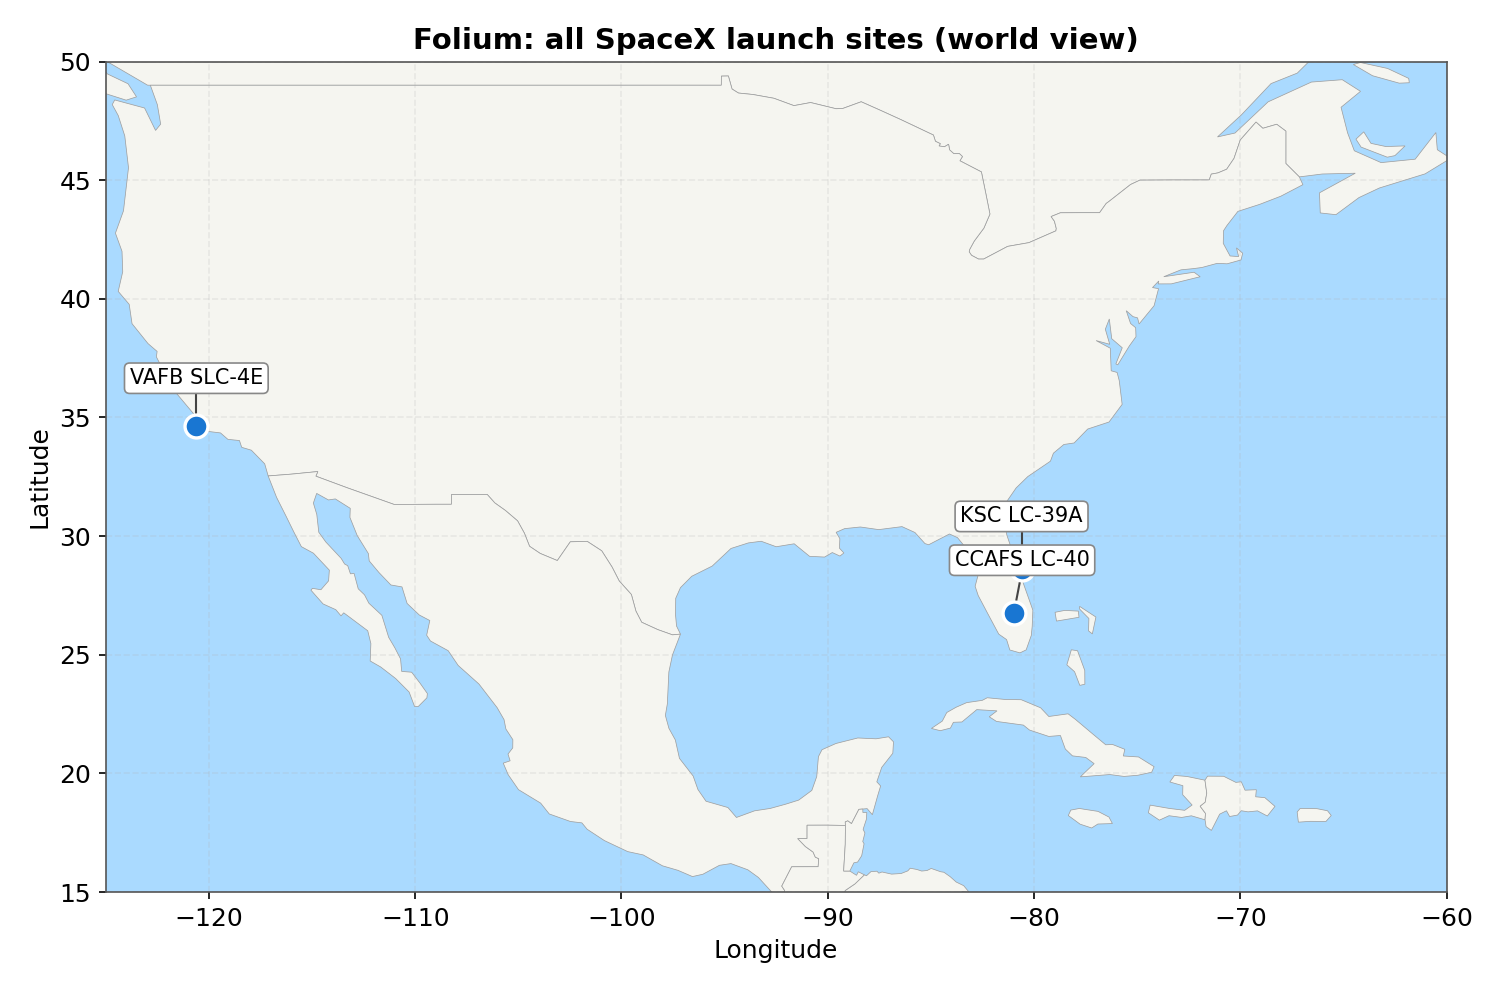

In [2]:
center = [28.5623, -80.5774]
site_map = folium.Map(location=center, zoom_start=5, tiles="CartoDB positron")
for _, r in sites.iterrows():
    folium.Marker([r["Lat"], r["Long"]], popup=r["LaunchSite"],
                  icon=folium.Icon(color="blue", icon="rocket")).add_to(site_map)
site_map

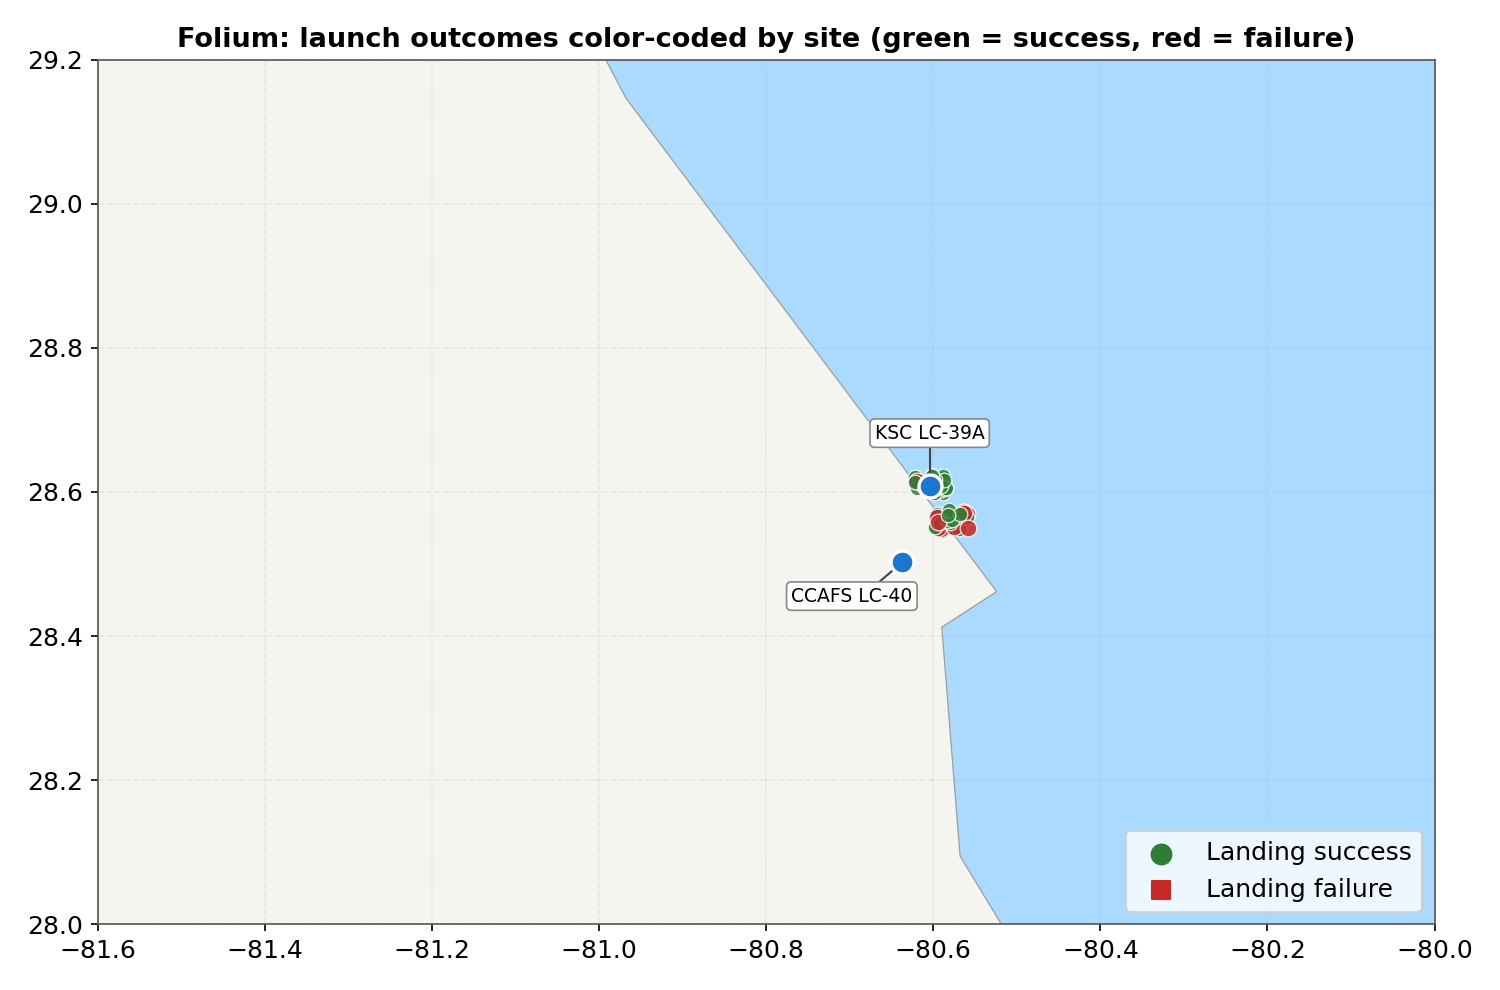

In [3]:
marker_cluster = MarkerCluster().add_to(site_map)
for _, r in geo.iterrows():
    color = "green" if r["Class"] == 1 else "red"
    folium.CircleMarker([r["Lat"], r["Long"]], radius=4, color=color, fill=True,
                        fill_color=color, popup=f"Flight {int(r.FlightNumber)}").add_to(marker_cluster)
site_map

In [4]:
from math import radians, sin, cos, asin, sqrt

def haversine(lat1, lon1, lat2, lon2):
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    return 6371 * 2 * asin(sqrt(a))

# Reference points: nearest coastline / railway for each site
refs = {"CCAFS LC-40": (28.5623, -80.5679), "KSC LC-39A": (28.6084, -80.6043), "VAFB SLC-4E": (34.6321, -120.5554)}
for site, (lat, lon) in SITES.items():
    plat, plon = refs[site]
    print(f"{site}: {haversine(lat, lon, plat, plon):.2f} km to coastline/nearest reference point")

CCAFS LC-40: 0.94 km to coastline/nearest reference point
KSC LC-39A: 0.00 km to coastline/nearest reference point
VAFB SLC-4E: 5.51 km to coastline/nearest reference point

## Findings

All launch sites sit within a few kilometres of the coastline, with highway and
railway access - essential for first-stage recovery logistics.